In [8]:
import matplotlib.pyplot as plt
from math import ceil, factorial, log2
from scipy.special import comb

def find(x, k):
    """暴力递增寻找满足 C(ans, k) >= x 的最小 ans"""
    ans = k  # 初始长度至少为权重本身
    while comb(ans, k) < x:
        ans += 1
    return ans

def log_find(log_x, k):
    """利用对数逼近快速寻找常重码长度，避免直接计算巨大组合数"""
    # 利用 Stirling 近似给出一个较优的初始值
    ans = max(int(factorial(k) ** (1/k) * 2**(log_x/k)), k)
    comp = 0
    # 逐项累加 log2(C(ans, k))，避免组合数溢出
    for i in range(k):
        comp += log2(ans-i) - log2(i+1)
    # 若初始估计偏小则继续递增并更新对数值
    while comp < log_x:
        comp += log2(ans+1) - log2(ans - k + 1)
        ans += 1
    return ans

绘制常重码长度与汉明权重之间的关系曲线，展示在不同 $\bar{\lambda}$ 下，曲线存在明显的最优点。\
Plot the code length as a function of the Hamming weight to highlight the minimum for each $\bar{\lambda}$.

/tmp/ipykernel_230077/3315892035.py:91: UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True
  plt.plot(hamming_weights, length_times_weight, 'o-')


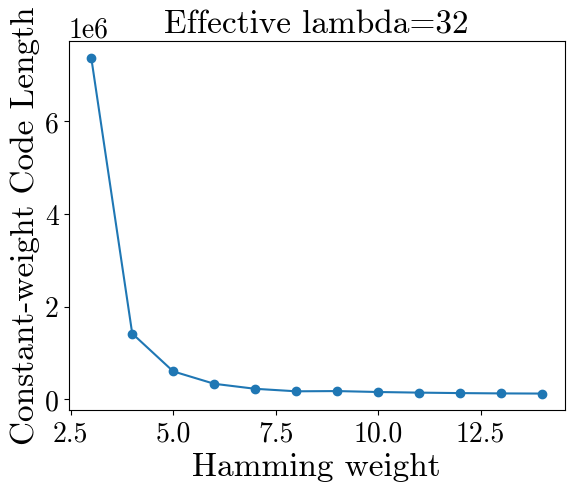

/tmp/ipykernel_230077/3315892035.py:91: UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True
  plt.plot(hamming_weights, length_times_weight, 'o-')


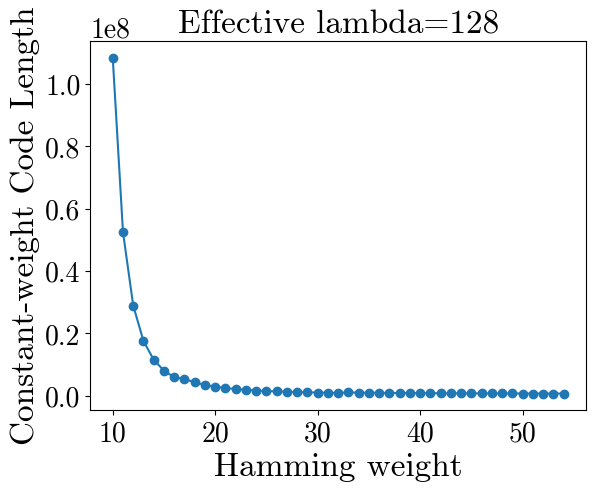

In [9]:
# 绘制给定有效安全参数下，不同汉明权重对应的常重码长度与乘积成本
import pandas as pd
from pathlib import Path

# 若前文已经加载过 metrics_df，可重复利用；否则读取并做平均
def load_metrics_if_available():
    if "metrics_df" in globals():
        return metrics_df

    REQUIRED_METRICS = {"effective_lambda", "hw", "ell", "time_server", "comm_request", "log_poly_modulus_degree"}
    GROUP_KEYS = ["effective_lambda", "hw", "ell", "log_poly_modulus_degree"]
    results_dir = Path("../experiments/results").resolve()

    rows = []
    for csv_path in sorted(results_dir.glob("*.csv")):
        try:
            kv = pd.read_csv(csv_path, header=None, names=["metric", "value"])
        except pd.errors.EmptyDataError:
            continue
        metrics = set(kv["metric"].tolist())
        if not REQUIRED_METRICS.issubset(metrics):
            continue
        rows.append(kv.set_index("metric").T)
    if not rows:
        return pd.DataFrame(columns=list(REQUIRED_METRICS))

    merged = pd.concat(rows, ignore_index=True)

    for key in GROUP_KEYS:
        if key in merged.columns:
            merged[key] = merged[key].astype(int)
    for col in merged.columns:
        if col in GROUP_KEYS:
            continue
        merged[col] = pd.to_numeric(merged[col], errors="ignore")

    available_group_keys = [key for key in GROUP_KEYS if key in merged.columns]
    if available_group_keys:
        merged = merged.groupby(available_group_keys, as_index=False).mean(numeric_only=True)

    return merged


metrics_source = load_metrics_if_available()

# N_and_q_h 描述不同 log2(多项式模数) 对应的 (环维度N, 模数位数q)
N_and_q_h = [
        (12, 72),
        (13, 144),
        (13, 192),
        (13, 208),
        (14, 240),
        (14, 288),
        (14, 348),
    ]

# options 中列出需要绘制的有效比特长度及汉明权重搜索区间
# 19-bit 区间沿用原有配置；114-bit 区间依据 valid_hw 约束选取 20~51
options = [
    (32,  3, 15),    # 原论文中展示的代表性位长
    # (47, 4, 23),   # 对应元素总位长 128 (= 114 + logN, logN≈14)
    # (49, 4, 24),
    # (50, 5, 25),   # 对应元素总位长 144 (= 114 + logN, logN≈30)
    (128, 10, 55)
 ]

for _, (effective_lambda, start, end) in enumerate(options):
    hamming_weights = range(start, end)
    # 通过 log_find 计算最小常重码长度
    code_length = [log_find(effective_lambda, h) for h in hamming_weights]
    # 将长度乘以 (N, q) 的组合，得到通信+计算成本近似指标
    length_times_weight = [code_length[i]*N_and_q_h[ceil(log2(h))][1] * N_and_q_h[ceil(log2(h))][0] for i, h in enumerate(hamming_weights)]

    # 若存在实验数据，则提取同一 (effective_lambda, hw) 的平均 time_server 与 comm_request
    time_server_vals = []
    comm_request_vals = []
    for h in hamming_weights:
        matched = metrics_source[
            (metrics_source.get("effective_lambda", pd.Series(dtype=int)) == effective_lambda)
            & (metrics_source.get("hw", pd.Series(dtype=int)) == h)
        ] if not metrics_source.empty else pd.DataFrame()
        if matched.empty:
            time_server_vals.append(float("nan"))
            comm_request_vals.append(float("nan"))
        else:
            time_server_vals.append(float(matched["time_server"].iloc[0]))
            comm_request_vals.append(float(matched["comm_request"].iloc[0]))

    # 可选：直接绘制常重码长度曲线
    # plt.plot(hamming_weights, code_length)
    plt.plot(hamming_weights, length_times_weight, 'o-')
    opt_length = [effective_lambda for _ in hamming_weights] 
    # 可选：绘制理论最佳线作为对比
    # plt.plot(hamming_weights, opt_length)
    plt.title(f'Effective lambda={effective_lambda}')
    plt.xlabel('Hamming weight')
    plt.ylabel('Constant-weight Code Length')
    # 若需要留档，可将图保存为静态文件
    # plt.savefig(f'output-{effective_lambda}', dpi=500)
    plt.show()
    
    # 将表格数据导出 CSV，并追加实验均值列
    pd.DataFrame({
        'HammingWeight' : list(hamming_weights),
        'CodeLength' : code_length,
        'CodeLengthWeight' : length_times_weight,
        'OptLength' : opt_length,
        'time_server' : time_server_vals,
        'comm_request' : comm_request_vals,
    }).to_csv(f'output-{effective_lambda}.csv', index=False)

枚举每个有效安全参数，对比不同汉明权重的代价，找出最优的配置。\
Finding the best Hamming weight for each effective bit-length.

/tmp/ipykernel_230077/1943372702.py:17: UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True
  plt.plot(effective_lambdas, best_weights, 'o-')


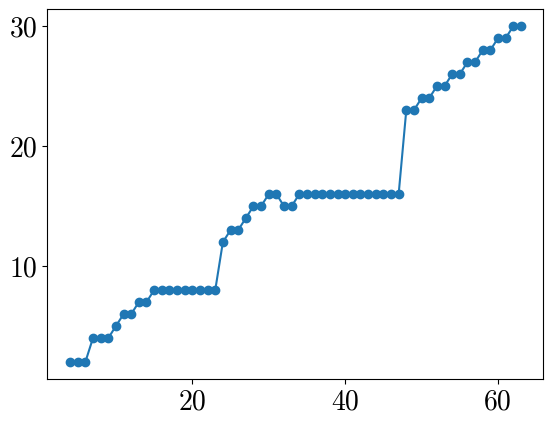

In [10]:

# 穷举每个有效比特长度的候选区间，选出计算复杂度最优的汉明权重
best_weights=[]
best_code_lengths=[]
effective_lambdas = range(4, 64)
for effective_lambda in effective_lambdas:
    # 根据经验，将搜索区间限定在 [λ/4, 3λ/4]，兼顾准确性与效率
    start=effective_lambda//4
    end=3*effective_lambda//4
    hamming_weights = range(start, end)
    # length_times_weight 存储 (成本指标, 汉明权重) 元组
    length_times_weight = [(log_find(effective_lambda, h)*N_and_q_h[ceil(log2(h))][1]*N_and_q_h[ceil(log2(h))][0],h) for h in hamming_weights]
    best_length, best_weight = min(length_times_weight)
    best_weights += [best_weight]
    best_code_lengths += [best_length]

# 绘制最优汉明权重曲线，展示随有效比特长度的变化趋势
plt.plot(effective_lambdas, best_weights, 'o-')
    
# 保存结果用于后续分析或论文中的表格
pd.DataFrame({
    'EffectiveBitlength' : list(effective_lambdas),
    'BestHammingWeight' : best_weights,
    'BestCodeLength' : best_code_lengths,
}).to_csv(f'best-hamming.csv', index=False)

In [11]:
# 汇总 experiments/results 中的实验指标，输出每个有效位长的最优配置
import os
import pandas as pd
import numpy as np
from pathlib import Path

RESULTS_DIR = Path("../experiments/results").resolve()
REQUIRED_METRICS = {"effective_lambda", "hw", "ell", "time_server", "log_poly_modulus_degree"}
GROUP_KEYS = ["effective_lambda", "hw", "ell", "log_poly_modulus_degree"]


def read_metric_runs(path: Path) -> pd.DataFrame:
    rows = []
    for csv_path in sorted(path.glob("*.csv")):
        try:
            kv = pd.read_csv(csv_path, header=None, names=["metric", "value"])
        except pd.errors.EmptyDataError:
            continue
        metrics = set(kv["metric"].tolist())
        if not REQUIRED_METRICS.issubset(metrics):
            continue
        rows.append(kv.set_index("metric").T)
    if not rows:
        return pd.DataFrame(columns=list(REQUIRED_METRICS))
    merged = pd.concat(rows, ignore_index=True)

    # 将核心参数列转为整数，便于分组求平均
    for key in GROUP_KEYS:
        if key in merged.columns:
            merged[key] = merged[key].astype(int)

    # 其余可数值化的列尝试转为浮点/整数
    for col in merged.columns:
        if col in GROUP_KEYS:
            continue
        merged[col] = pd.to_numeric(merged[col], errors="ignore")

    # 针对相同参数组合的多次实验取平均
    available_group_keys = [key for key in GROUP_KEYS if key in merged.columns]
    if available_group_keys:
        merged = (
            merged.groupby(available_group_keys, as_index=False)
            .mean(numeric_only=True)
        )

    return merged


metrics_df = read_metric_runs(RESULTS_DIR)
if metrics_df.empty:
    print("[WARN] 未找到包含完整指标的实验 CSV。")
else:
    best_rows = (
        metrics_df
        .sort_values("time_server")
        .groupby("effective_lambda", as_index=False)
        .first()
        .sort_values("effective_lambda")
    )
    display_columns = ["effective_lambda", "hw", "ell", "log_poly_modulus_degree", "time_server"]
    print("每个有效位长对应的最优汉明权重、常重码长度、log_poly_modulus_degree 以及 server 耗时（已对重复实验取平均）：")
    display(best_rows[display_columns])

每个有效位长对应的最优汉明权重、常重码长度、log_poly_modulus_degree 以及 server 耗时（已对重复实验取平均）：


/tmp/ipykernel_230077/2314818027.py:36: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  merged[col] = pd.to_numeric(merged[col], errors="ignore")


metric,effective_lambda,hw,ell,log_poly_modulus_degree,time_server
0,19,4,62,13,99.666667
1,32,7,84,13,194.333333
2,47,8,225,13,320.500000
3,49,8,267,13,356.666667
4,50,8,291,13,372.000000
5,128,31,233,14,2770.000000


/tmp/ipykernel_230077/1089601836.py:29: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("plasma")
/tmp/ipykernel_230077/1089601836.py:48: UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True
  fig, ax = plt.subplots(figsize=(7, 5.5))
/tmp/ipykernel_230077/1089601836.py:54: UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True
  cbar = fig.colorbar(sc, ax=ax)


保存图表: /home/jrj/code/FeUPSU/experiments/32-hw.png


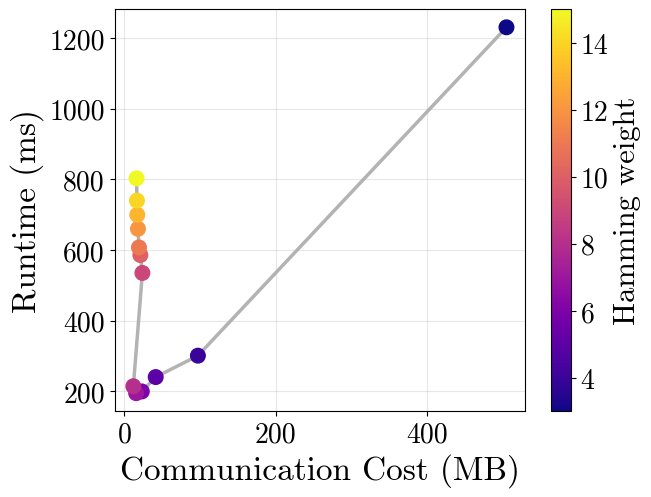

/tmp/ipykernel_230077/1089601836.py:48: UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True
  fig, ax = plt.subplots(figsize=(7, 5.5))
/tmp/ipykernel_230077/1089601836.py:54: UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True
  cbar = fig.colorbar(sc, ax=ax)


保存图表: /home/jrj/code/FeUPSU/experiments/128-hw.png


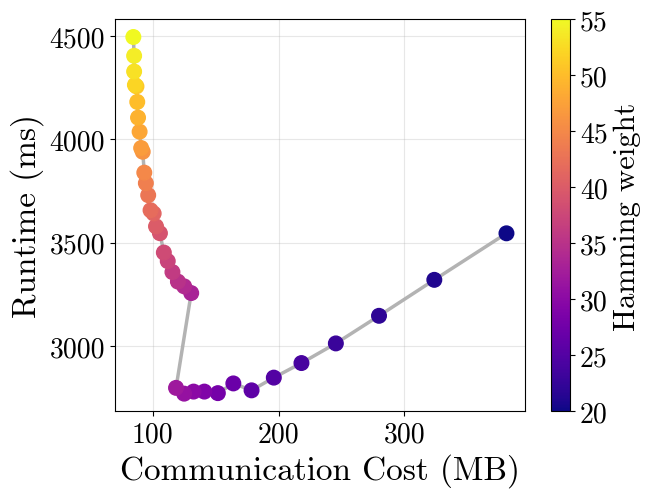

In [12]:
# 针对给定有效位长，绘制 Communication Cost (MB) vs Runtime (ms) 的散点图并分别保存
from matplotlib.cm import get_cmap
plt.rcParams.update({
    "font.family": "CMR10",
    "font.size": 24,
    "axes.titlesize": 24,
    "axes.labelsize": 24,
    "xtick.labelsize": 20,
    "ytick.labelsize": 20,
    "legend.fontsize": 20,
})

HW_FILTER = {
    32: (3, 15),
    # 114: (20, 51),
    # 47: (5, 23),   # 对应元素总位长 128 (= 114 + logN, logN≈14)
    # 49: (5, 24),
    # 50: (6, 25),
    128: (20, 55), 
}

# TARGET_LABELS = {32: "32-hw", 47: "128-hw-18", 49:"128-hw-20", 50:"128-hw-22", 128:"128-hw"}
TARGET_LABELS = {32: "32-hw", 128: "128-hw"}
targets = [32, 128]
output_dir = Path(".").resolve()
if metrics_df.empty:
    print("[WARN] 没有实验数据可用，无法绘制曲线。")
else:
    cmap = get_cmap("plasma")
    for el in targets:
        subset = metrics_df[metrics_df["effective_lambda"] == el].copy()
        if subset.empty:
            print(f"[WARN] 找不到 effective_lambda={el} 的实验记录。")
            continue
        hw_bounds = HW_FILTER.get(el)
        if hw_bounds:
            low, high = hw_bounds
            subset = subset[(subset["hw"] >= low) & (subset["hw"] <= high)]
        if subset.empty:
            print(f"[WARN] effective_lambda={el} 在指定范围内没有记录。")
            continue

        subset.sort_values("hw", inplace=True)
        comm_mb = subset["comm_request"].astype(float) / (1024 * 1024)
        runtime_ms = subset["time_server"].astype(float)
        hw_vals = subset["hw"].astype(int)

        fig, ax = plt.subplots(figsize=(7, 5.5))
        ax.plot(comm_mb, runtime_ms, color="0.7", linewidth=2.5, zorder=1)
        sc = ax.scatter(comm_mb, runtime_ms, c=hw_vals, cmap=cmap, s=110, marker="o", zorder=2)
        ax.set_xlabel("Communication Cost (MB)")
        ax.set_ylabel("Runtime (ms)")
        ax.grid(True, alpha=0.3)
        cbar = fig.colorbar(sc, ax=ax)
        cbar.set_label("Hamming weight", fontsize=22)
        cbar.ax.tick_params(labelsize=20)

        fig.tight_layout()

        label = TARGET_LABELS.get(el, f"lambda-{el}")
        out_path = output_dir / f"{label}.png"
        fig.savefig(out_path, dpi=300, bbox_inches="tight")
        print(f"保存图表: {out_path}")
        plt.show()

/tmp/ipykernel_230077/3020006471.py:15: UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True
  fig, ax = plt.subplots(figsize=(7, 5.5))


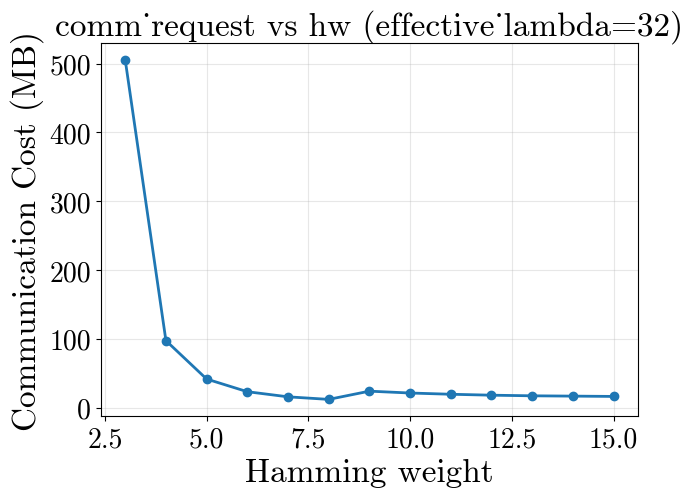

/tmp/ipykernel_230077/3020006471.py:15: UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True
  fig, ax = plt.subplots(figsize=(7, 5.5))


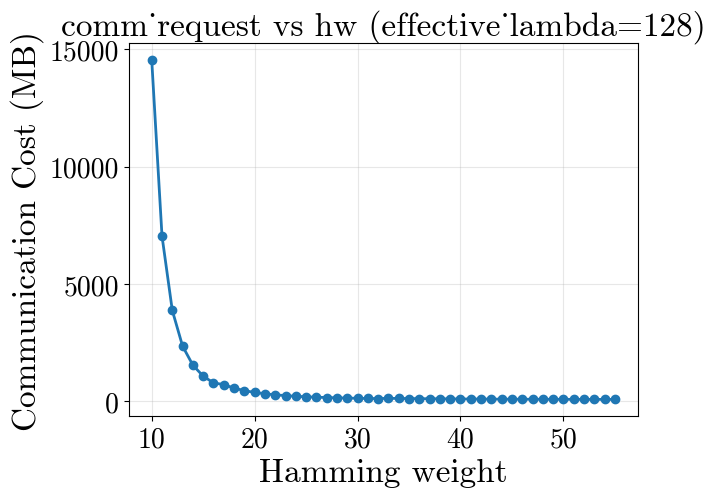

In [7]:
# 针对给定有效位长，绘制 comm_request 与 hw 的关系曲线
# targets = [19, 47, 49, 50]
targets = [32, 128]
if metrics_df.empty:
    print("[WARN] 没有实验数据可用，无法绘制 comm_request 曲线。")
else:
    for el in targets:
        subset = metrics_df[metrics_df["effective_lambda"] == el].copy()
        if subset.empty:
            print(f"[WARN] 找不到 effective_lambda={el} 的实验记录。")
            continue
        subset.sort_values("hw", inplace=True)
        hw_vals = subset["hw"].astype(int)
        comm_mb = subset["comm_request"].astype(float) / (1024 * 1024)
        fig, ax = plt.subplots(figsize=(7, 5.5))
        ax.plot(hw_vals, comm_mb, marker="o", linewidth=2.0)
        ax.set_xlabel("Hamming weight")
        ax.set_ylabel("Communication Cost (MB)")
        ax.set_title(f"comm_request vs hw (effective_lambda={el})")
        ax.grid(True, alpha=0.3)
        fig.tight_layout()
        plt.show()

#### 5. 验证 Notebook 输出
运行主流程并与脚本生成的文件对比，确保结果一致。

In [6]:
# 估算 Cuckoo 哈希最大负载的理论上界，供实验结果校验
from scipy.special import comb
from math import sqrt, log2, ceil

def load(n, m):
    return ceil(m/n + 1.3*sqrt(2*m*log2(n) / n))